# Carte auto-organisatrice de Kohonen (SOM)

Même codec que le K-means — une image est encodée par l'indice de son prototype le plus proche — mais un apprentissage différent :

| | K-means | Kohonen |
|---|---|---|
| Mise à jour | batch : moyenne de tout le cluster | stochastique : un exemple à la fois |
| Qui bouge | le gagnant seul | le gagnant **et ses voisins**, atténués |
| Topologie | aucune | grille 2D — c'est elle qui définit « voisin » |

Règle de mise à jour, appliquée à **tous** les neurones à chaque tirage d'un exemple `Sj` de gagnant `k` :

$$W_i \leftarrow W_i + \alpha \cdot e^{-\frac{\|C_i - C_k\|^2}{2\gamma}} \cdot (S_j - W_i)$$

où $C_i$ est la position du neurone $i$ **sur la grille** (pas dans l'espace des images), $\alpha$ le pas d'apprentissage et $\gamma$ la largeur du voisinage.

Le facteur exponentiel vaut 1 pour le gagnant et s'écrase avec l'éloignement : le gagnant prend la correction pleine, ses voisins une version atténuée, les neurones lointains rien.

**Conséquence :** deux neurones voisins sur la grille étant toujours tirés ensemble, ils apprennent des prototypes proches. Le dictionnaire devient une carte lisible — et c'est ce qui remplace la PCA du K-means pour visualiser l'espace latent.

## Imports

In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

# data_import.py vit dans src/, ce notebook dans src/kohonen/ : sans ça,
# `import data_import` échoue.
sys.path.insert(0, str(Path.cwd().parent))
from data_import import load_dataset

from utils.kohonen import (
    assign_clusters,
    compute_inertia,
    fit_kohonen,
    grid_coords,
)
from utils.codec import encode, decode
from utils.metrics import (
    compute_compression_ratio,
    mean_squared_error,
    mse_from_inertia,
    reconstruct,
)
from utils.registry import save_model, load_model, list_models
from utils.visualization import (
    plot_class_distribution,
    plot_heatmap,
    plot_inertia,
    plot_latent_space,
    plot_prototype_map,
    show_reconstructions,
)

IMAGE_DIM = 784

## Hyperparamètres

- `ROWS`, `COLS` : forme de la grille. `k = ROWS · COLS` prototypes, comme le K de K-means — mais ici leur **disposition** compte.
- `TOPOLOGY` : `"hex"` (défaut) ou `"rect"`. En hexagonal, les lignes impaires sont décalées d'une demi-case et les **6 voisins d'un neurone sont à distance exactement 1**. En carré, un neurone a 4 voisins à distance 1 mais 4 diagonales à 1,41 : ses voisins ne sont pas équivalents, et la carte s'étire selon les axes. C'est la grille classique de Kohonen, et la seule où « voisin » a un sens unique.
- `ALPHA` : pas d'apprentissage. Trop grand, le dernier exemple vu efface les précédents ; trop petit, rien ne bouge.
- `GAMMA` : largeur du voisinage, en cases de grille. À `GAMMA=1`, un voisin direct reçoit 61 % de la correction du gagnant et une case à 3 de distance 1 %. Trop petit → le SOM dégénère en K-means stochastique (aucune organisation) ; trop grand → tous les neurones apprennent la même chose.
- `N_EPOCHS` : passes sur les données. Une époque = chaque exemple présenté une fois, dans un ordre remélangé.

`alpha` et `gamma` restent **constants**, comme dans la formule.

In [2]:
ROWS, COLS = 10, 10
TOPOLOGY = "hex"
N_SAMPLES = 10000
ALPHA = 0.1
GAMMA = 1.0
N_EPOCHS = 8
SEED = 42

K = ROWS * COLS
print(f"Grille {ROWS}x{COLS} = {K} neurones ({TOPOLOGY})")
print(f"Taux de compression : {compute_compression_ratio(K):.0f}x "
      f"({IMAGE_DIM * 8} bits/image -> {int(np.ceil(np.log2(K)))} bits de code)")

# Vérification de la topologie : en hexagonal, les 6 voisins d'un neurone
# doivent tomber à distance exactement 1 — c'est ce qui rend gamma lisible.
coords = grid_coords(ROWS, COLS, TOPOLOGY)
center = (ROWS // 2) * COLS + COLS // 2
d = np.linalg.norm(coords - coords[center], axis=1)
print(f"Voisins à distance 1 du neurone central : {int(np.sum(np.abs(d - 1) < 1e-4))}")


Grille 10x10 = 100 neurones (hex)
Taux de compression : 896x (6272 bits/image -> 7 bits de code)
Voisins à distance 1 du neurone central : 6


## Entraînement sur les deux datasets

MNIST (chiffres 0-9) et Quick, Draw! (cat, apple, car) sortent tous deux de `data_import.load_dataset` au même format `(n, 784)` float32 dans `[0, 1]` : le même code s'applique aux deux sans rien changer.

In [3]:
DATASETS = ["mnist", "quickdraw"]
RESULTS = {}

for key in DATASETS:
    ds = load_dataset(key)
    X_train = ds.X_train[:N_SAMPLES]
    y_train = ds.y_train[:N_SAMPLES]

    print(f"\n=== {ds.describe()} ===")
    weights, labels, history = fit_kohonen(
        X=X_train,
        rows=ROWS,
        cols=COLS,
        n_epochs=N_EPOCHS,
        alpha=ALPHA,
        gamma=GAMMA,
        seed=SEED,
        verbose=True,
        return_history=True,
        topology=TOPOLOGY,
    )

    RESULTS[key] = {
        "ds": ds,
        "X_train": X_train,
        "y_train": y_train,
        "weights": weights,
        "labels": labels,
        "history": history,
        # MNIST étiquette des chiffres, Quick, Draw! des objets : le libellé des
        # axes doit suivre, « Chiffre réel » n'a aucun sens pour un chat.
        "y_label": "Chiffre réel" if key == "mnist" else "Classe réelle",
    }
    print(f"MSE finale : {mse_from_inertia(history[-1], len(X_train)):.4f}")


=== mnist — 60000 train / 10000 test · 10 classes : 0, 1, 2, 3, 4, 5, 6, 7, 8, 9 ===


Époque 1/8 : inertie = 347463.9375


Époque 2/8 : inertie = 347627.0000


Époque 3/8 : inertie = 346265.4062


Époque 4/8 : inertie = 348566.7188


Époque 5/8 : inertie = 346567.4062


... (8 outputs left out)

Époque 5/8 : inertie = 535061.0000


Époque 6/8 : inertie = 533907.8750


Époque 7/8 : inertie = 535176.0625


Époque 8/8 : inertie = 536151.8750
MSE finale : 0.0684


## 1. Courbe d'entraînement

Le point **0** est l'état initial, avant la moindre mise à jour. Il compte : une époque, c'est déjà `N_SAMPLES` corrections, et à `alpha` constant le SOM a pratiquement convergé au bout de la première. Toute la descente tient donc dans le premier segment ; les époques suivantes oscillent autour d'un équilibre.

Cette oscillation est normale, et c'est une autre différence avec le K-means : là-bas l'inertie **est** la loss et ne peut que décroître, une remontée trahit un bug. Ici le SOM ne minimise pas l'inertie seule mais un compromis entre elle et la contrainte de voisinage — et comme `alpha` ne décroît jamais, chaque exemple continue de tirer les poids vers lui indéfiniment. Le SOM ne se fige pas : il fluctue autour de son équilibre. C'est la tendance qui compte, pas la monotonie.

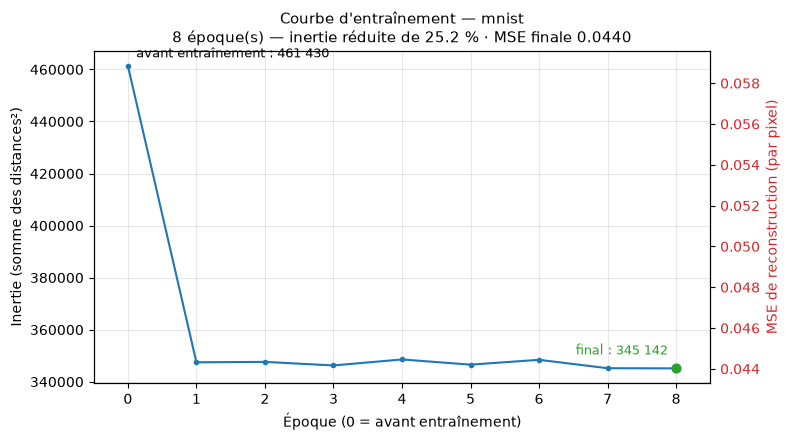

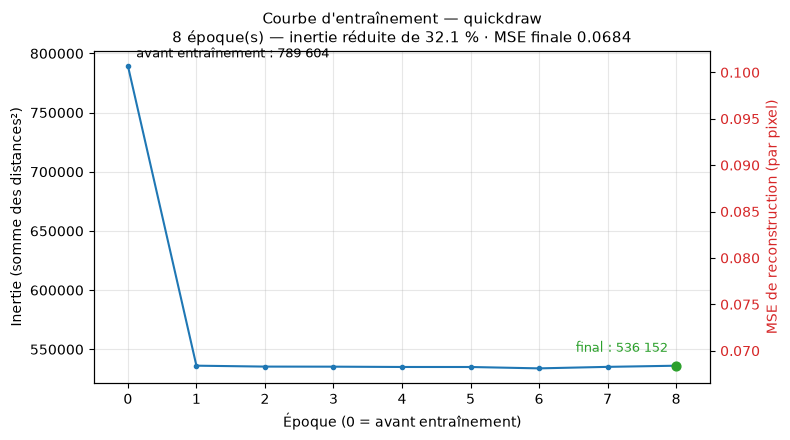

In [4]:
for key, r in RESULTS.items():
    plot_inertia(
        r["history"],
        n_samples=len(r["X_train"]),
        image_dim=IMAGE_DIM,
        title=f"Courbe d'entraînement — {key}",
    )

## 2. La carte : les feature vectors à leur place sur la grille

Chaque case montre ce que le neurone a appris. C'est la vue signature du SOM : **les cases voisines se ressemblent**, exactement ce que la règle de voisinage impose. Les variantes d'un même chiffre occupent une région connexe, et les formes intermédiaires se rangent aux frontières.

La même vue pour un K-means est une grille arbitraire : ses centroïdes n'ont pas de voisins, on les range par taille de cluster faute de mieux.

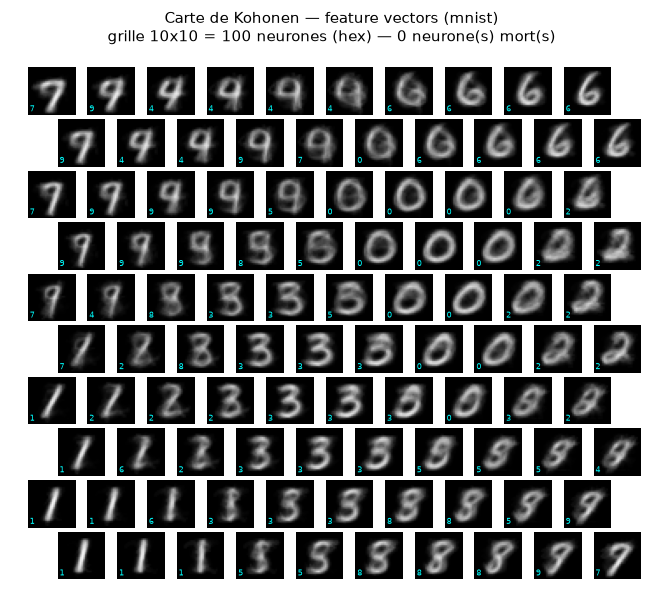

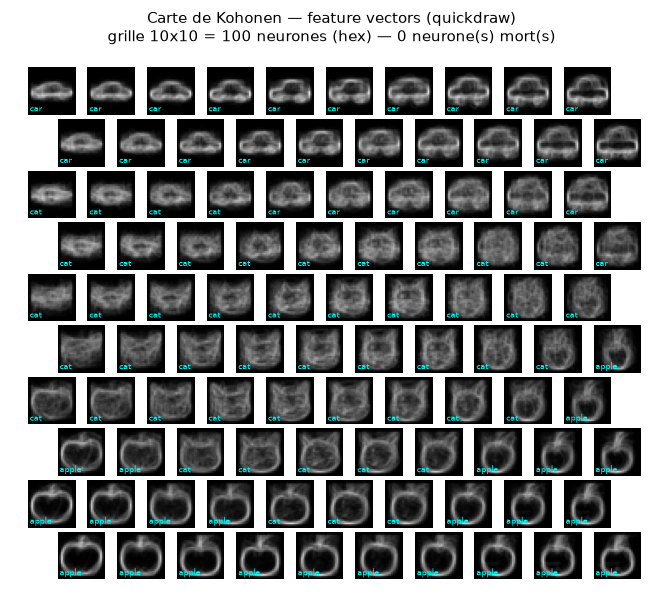

In [5]:
for key, r in RESULTS.items():
    plot_prototype_map(
        r["weights"], ROWS, COLS,
        cluster_labels=r["labels"],
        y_true=r["y_train"],
        class_names=r["ds"].class_names,
        topology=TOPOLOGY,
        title=f"Carte de Kohonen — feature vectors ({key})",
    )

### La même carte en heatmap : l'U-matrix

La carte des prototypes montre *ce que* chaque neurone a appris. La **U-matrix** montre autre chose, qu'aucune des deux vues précédentes ne donne : la **distance moyenne de chaque neurone à ses 6 voisins**.

- **Case sombre** → le neurone ressemble à ses voisins : on est à l'intérieur d'un groupe homogène.
- **Case claire** → il ne leur ressemble pas : on franchit une **frontière** entre deux groupes.

C'est l'information qui manque partout ailleurs : la grille est régulière, mais les distances réelles entre voisins ne le sont pas. Les crêtes claires dessinent donc les séparations que la topologie a dû étirer pour relier deux régions éloignées des données.

`color_by` accepte aussi `"density"` (images gagnées par neurone, les cases à 0 étant les neurones morts) et `"class"` (classe majoritaire).

⚠️ Une heatmap est une grille **rectangulaire**. Les voisinages sont bien calculés en hexagonal (6 voisins), mais l'affichage ne décale pas les lignes impaires : deux cases mitoyennes à l'écran sur deux lignes différentes ne sont pas forcément voisines. La carte des feature vectors ci-dessus, elle, respecte le décalage.

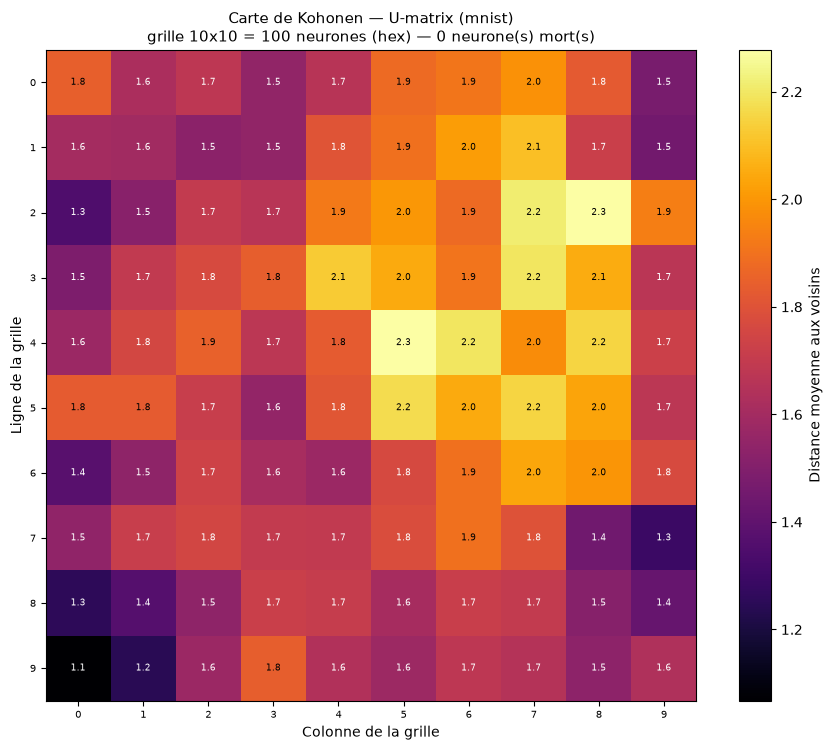

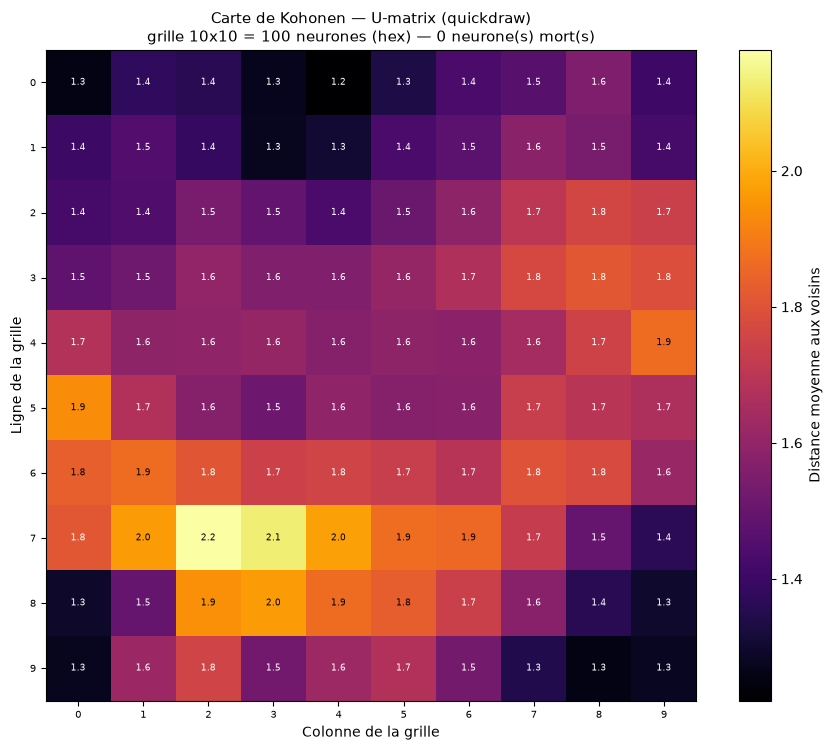

In [6]:
for key, r in RESULTS.items():
    plot_heatmap(
        r["weights"], ROWS, COLS,
        cluster_labels=r["labels"],
        color_by="umatrix",
        topology=TOPOLOGY,
        title=f"Carte de Kohonen — U-matrix ({key})",
    )

## 3. Espace latent

Le **même nuage que pour le K-means** : les images projetées en PCA, colorées par neurone à gauche et par classe réelle à droite, les prototypes en croix noires. La figure est directement comparable à celle du K-means.

**Pourquoi une PCA, alors que la grille du SOM est déjà une carte 2D ?** Parce que ses coordonnées sont *discrètes* : 100 neurones pour 10 000 images donnent 100 paquets de points, pas une nappe. La grille est une belle carte pour ranger des prototypes (section 2), un mauvais support pour un nuage.

**Ce que cette figure a en plus de celle du K-means : le maillage.** Chaque segment relie deux neurones *voisins sur la grille*, placés à la position de leurs feature vectors dans le plan PCA. On voit donc la carte se **replier à travers les données** :

| ce qu'on voit | ce que ça dit |
|---|---|
| maillage régulier et étalé | la grille couvre le nuage sans se tordre |
| segment long | deux voisins ont appris des choses très différentes — on saute une frontière |
| neurones serrés en paquet | plusieurs voisins sur le même mode des données |

Un K-means n'a pas cet objet : ses centroïdes n'ont aucun voisin, il n'y a rien à relier.

⚠️ **Le prix de la PCA.** Les 2 composantes ne retiennent qu'environ **17 % de la variance** de MNIST : le reste est écrasé, et des images très éloignées peuvent atterrir au même endroit. Deux neurones superposés à l'écran ne le sont pas forcément en 784 dimensions — c'est le **maillage**, et non la distance à l'écran, qui dit qui est voisin de qui.

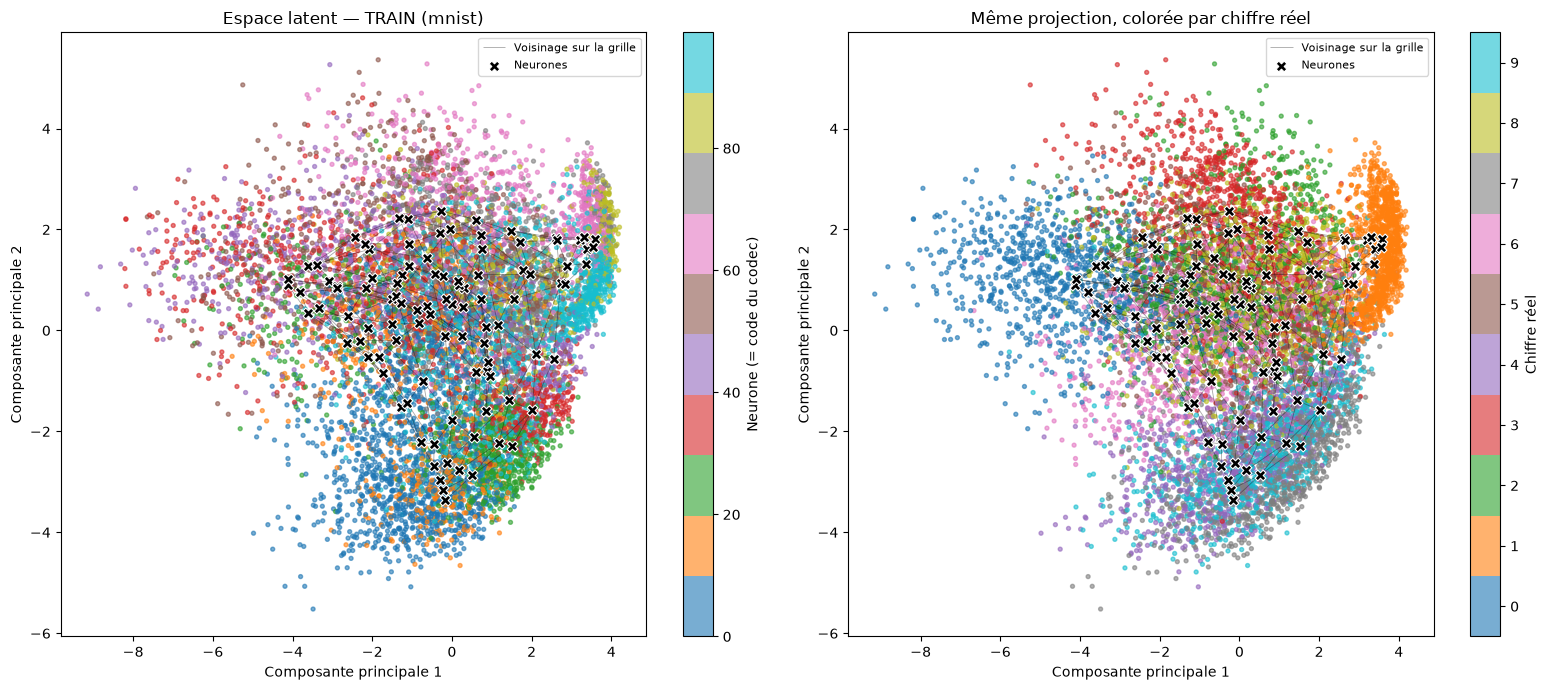

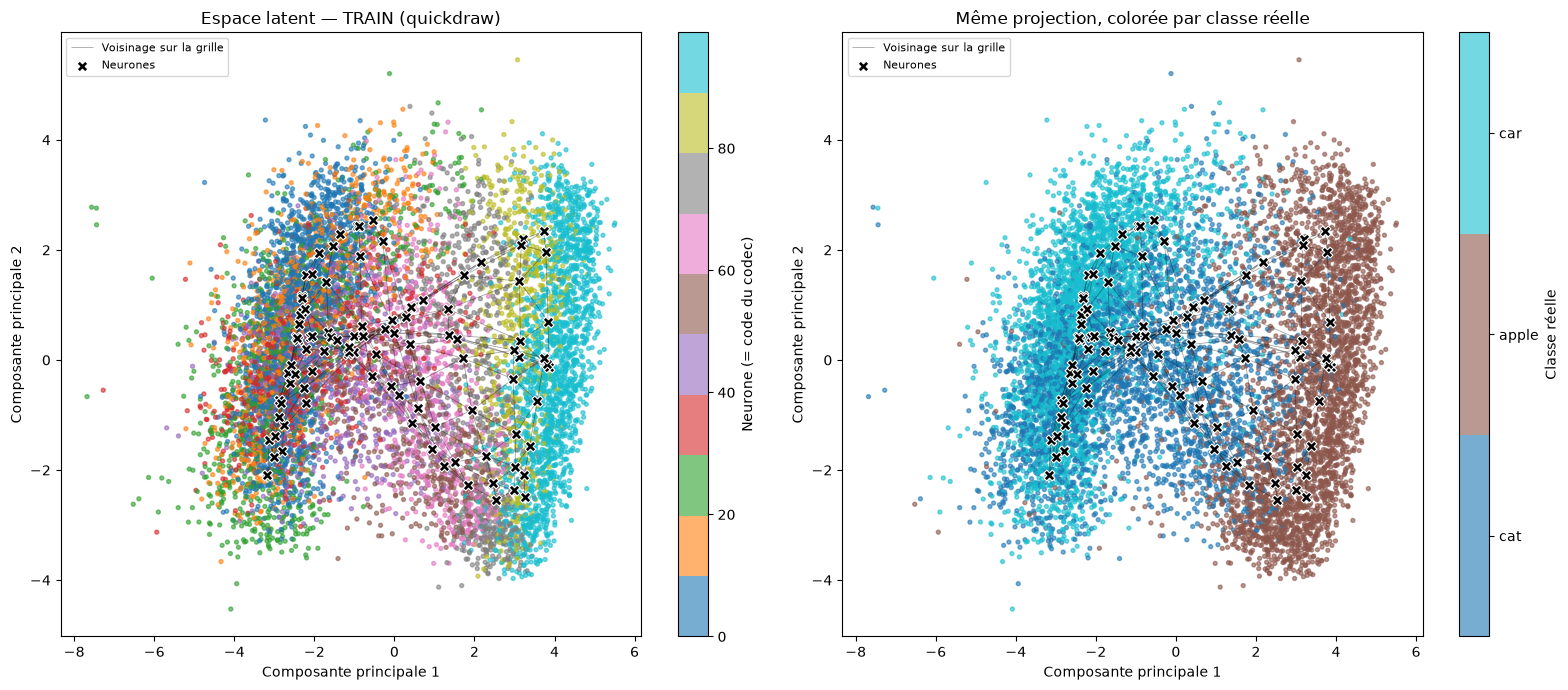

In [7]:
for key, r in RESULTS.items():
    plot_latent_space(
        r["X_train"], r["weights"], ROWS, COLS,
        y_true=r["y_train"],
        class_names=r["ds"].class_names,
        topology=TOPOLOGY,
        y_label=r["y_label"],
        title=f"Espace latent — TRAIN ({key})",
    )

### Généralisation : la même carte sur le test

Les poids ne bougent plus — on ne fait qu'encoder des images jamais vues. Si la carte du test ressemble à celle du train, le SOM a appris la structure des données et pas seulement ses exemples.

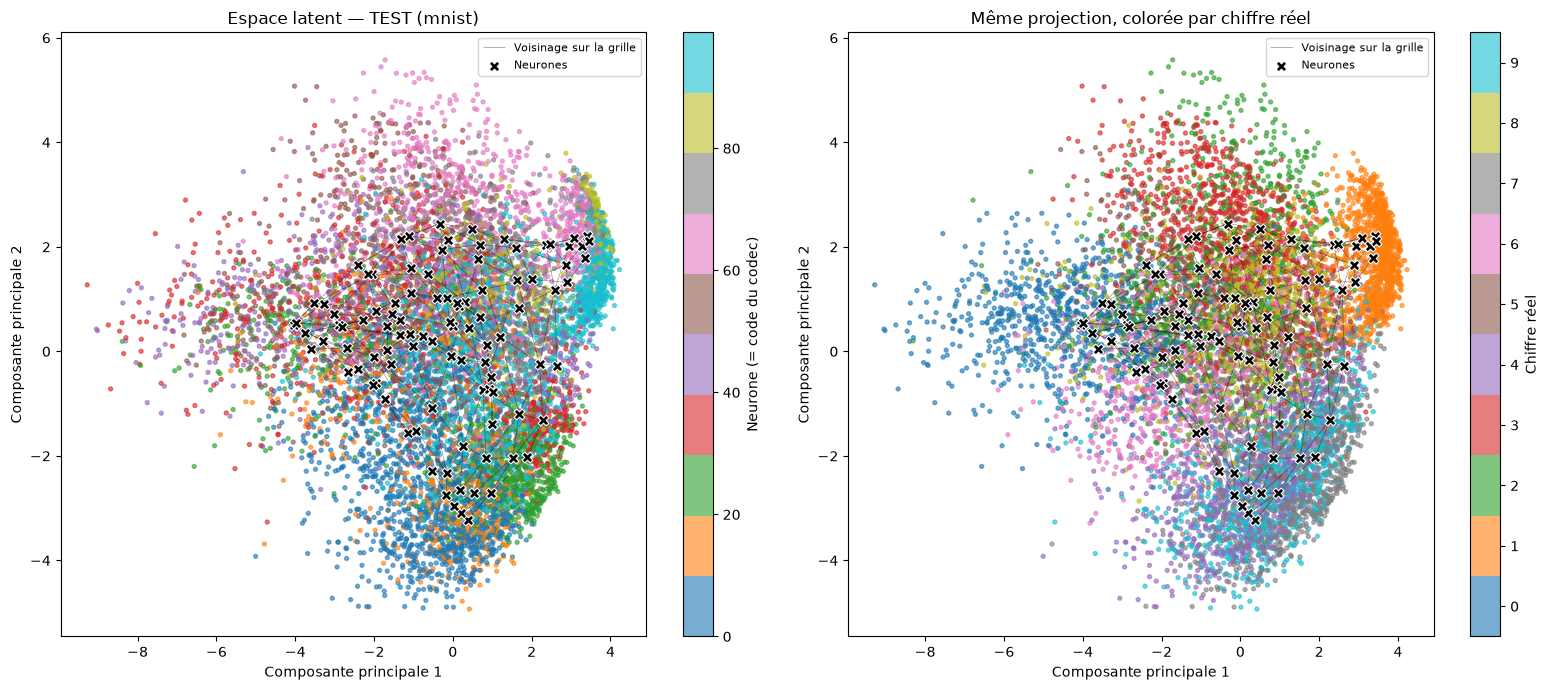

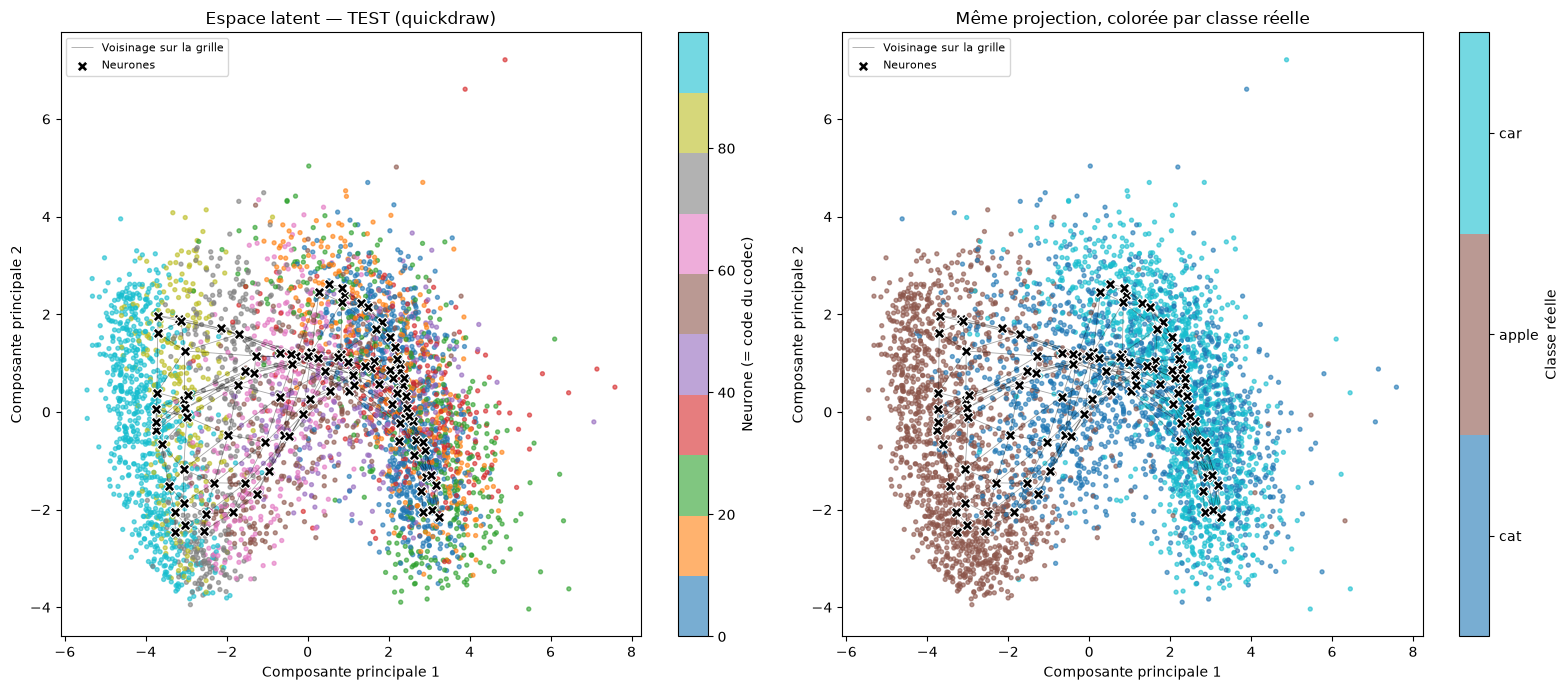

In [8]:
for key, r in RESULTS.items():
    ds = r["ds"]
    n_test = min(N_SAMPLES, len(ds.X_test))

    # Les poids sont figés : on ne fait qu'encoder des images jamais vues.
    plot_latent_space(
        ds.X_test[:n_test], r["weights"], ROWS, COLS,
        y_true=ds.y_test[:n_test],
        class_names=ds.class_names,
        topology=TOPOLOGY,
        y_label=r["y_label"],
        title=f"Espace latent — TEST ({key})",
    )

## 4. Distribution des classes réelles par neurone

Un groupe dominé par une seule barre = neurone pur ; plusieurs barres de hauteur voisine = neurone qui mélange des classes. C'est la vue qui répond à « mes neurones retrouvent-ils mes vraies classes ? », ce que l'inertie ne dit pas — elle ne mesure que la compression.

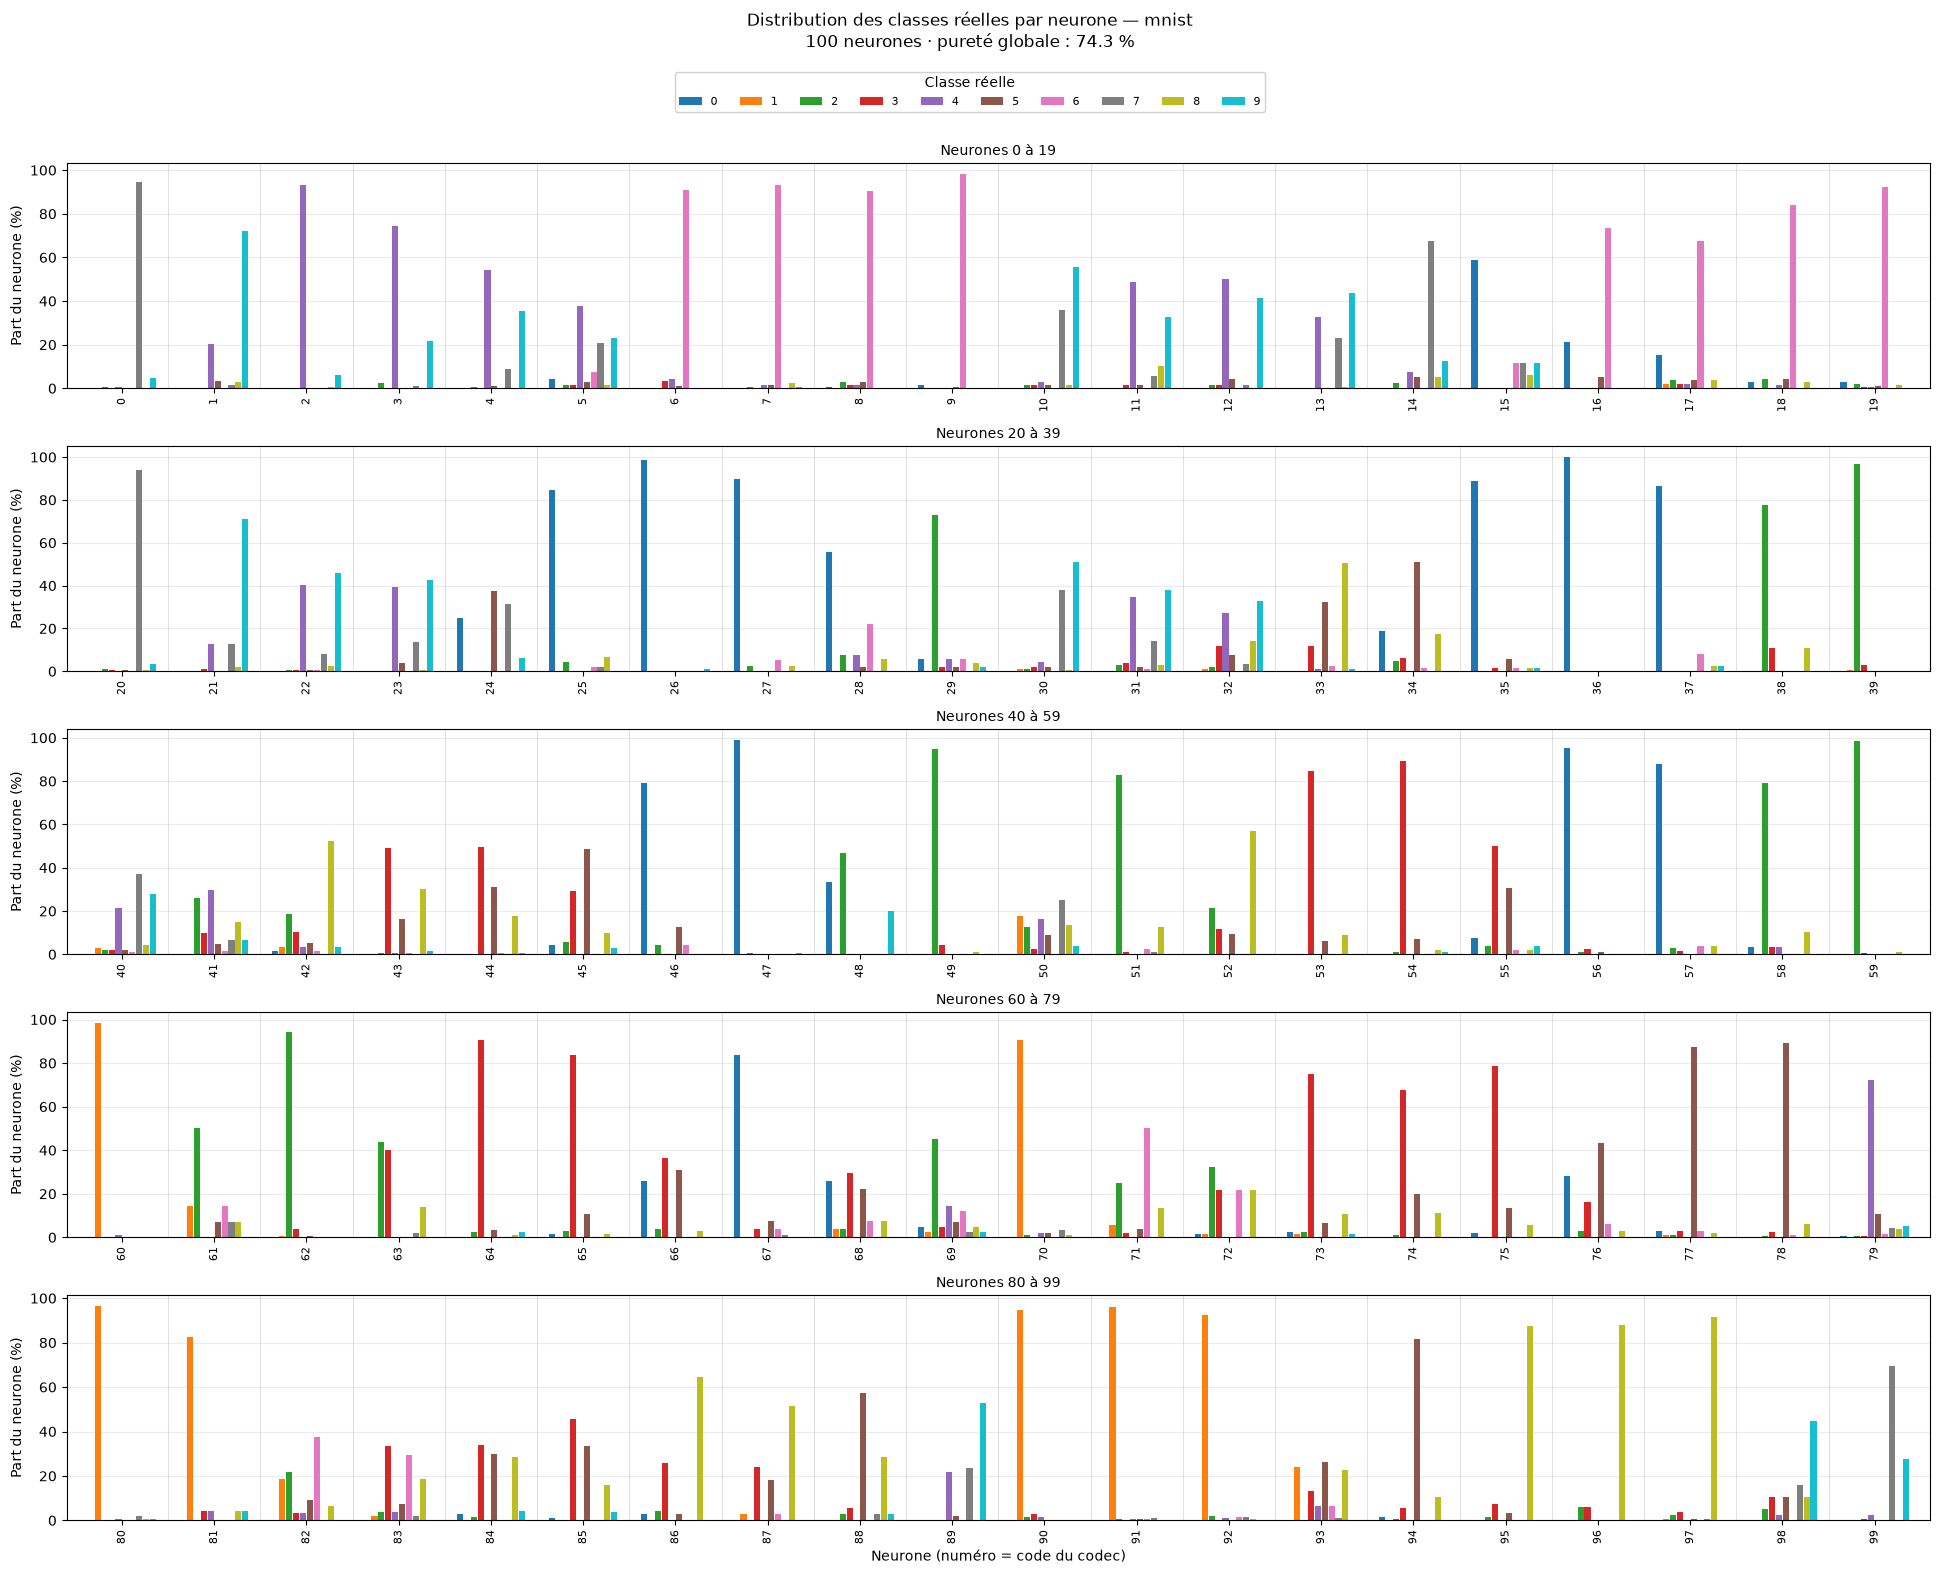

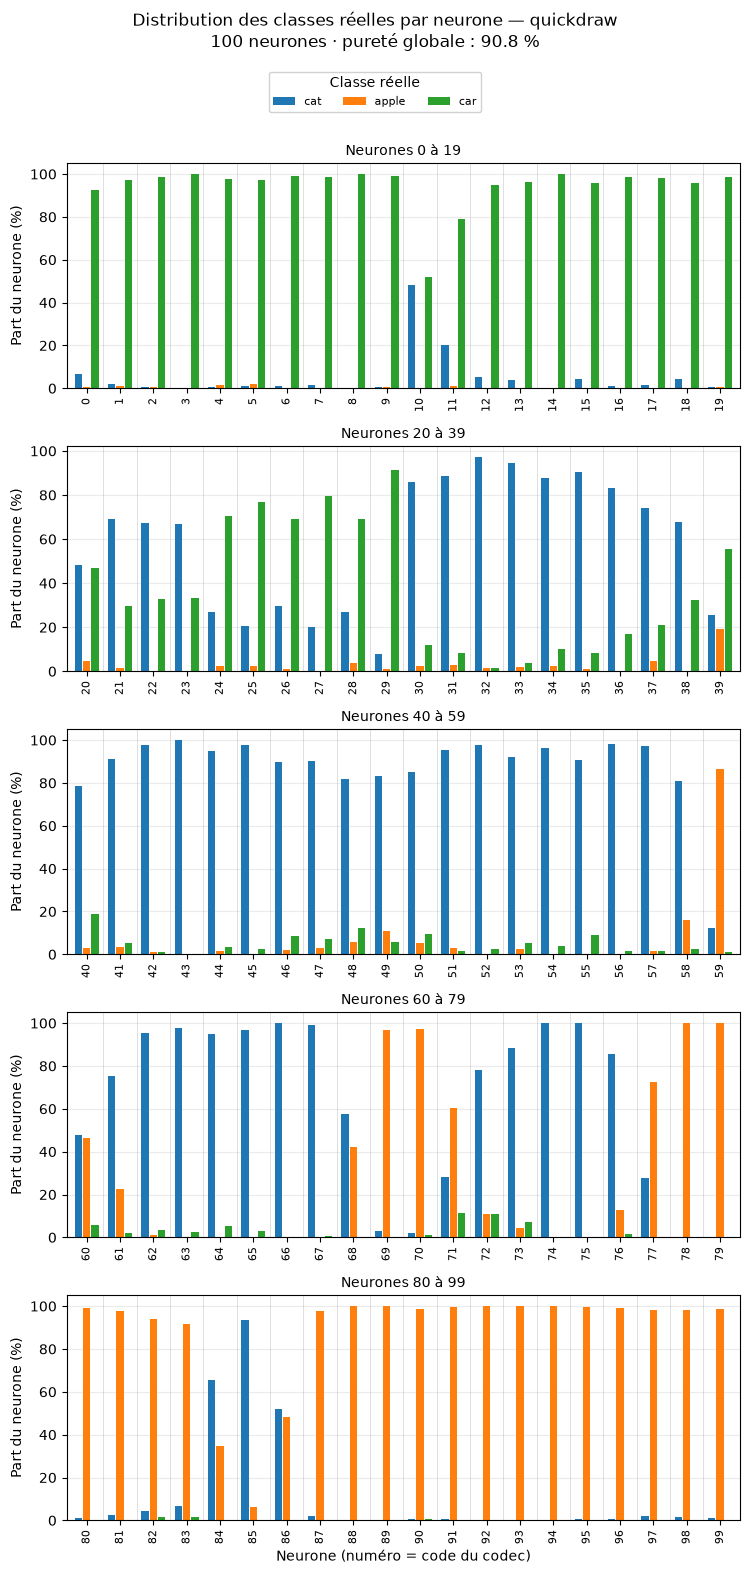

In [9]:
for key, r in RESULTS.items():
    plot_class_distribution(
        r["labels"], r["y_train"],
        class_names=r["ds"].class_names,
        k=K,
        normalize=True,
        title=f"Distribution des classes réelles par neurone — {key}",
    )

## 5. Compression / décompression

Le codec est identique à celui du K-means : le SOM organise ses prototypes sur une grille, mais cela ne change rien à la transmission — le code reste un entier.

- `encode(image, weights)` → l'indice du neurone gagnant : **7 bits** au lieu de 6272.
- `decode(code, weights)` → le feature vector de ce neurone, l'image reconstruite.

In [10]:
# Un aller-retour, image par image, pour voir le codec de près.
r = RESULTS["mnist"]
image = r["X_train"][0]

code = encode(image, r["weights"])
reconstruction = decode(code, r["weights"])

print(f"Image originale  : {image.shape} -> {image.nbytes} octets")
print(f"Code transmis    : {code}  (case grille {code // COLS}, {code % COLS})")
print(f"Reconstruction   : {reconstruction.shape}")
print(f"MSE de cette image : {mean_squared_error(image[None], reconstruction[None]):.4f}")

Image originale  : (784,) -> 3136 octets
Code transmis    : 75  (case grille 7, 5)
Reconstruction   : (784,)
MSE de cette image : 0.0481


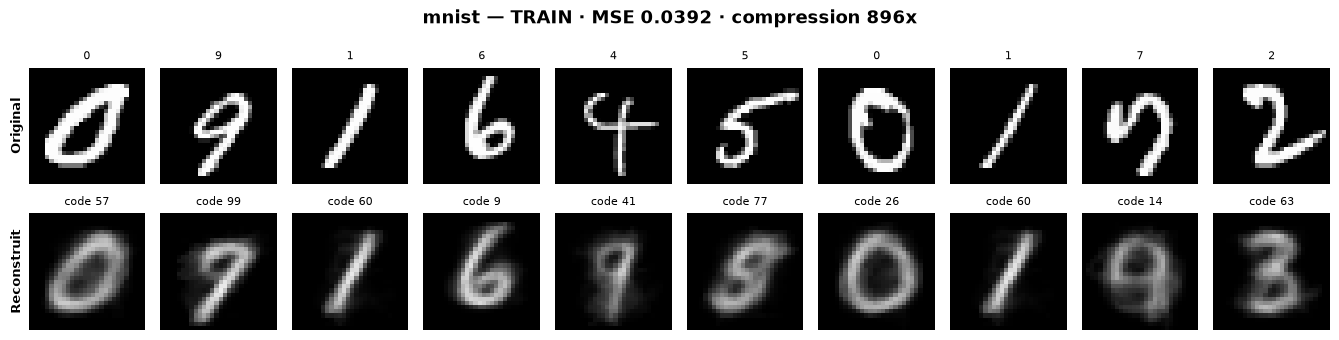

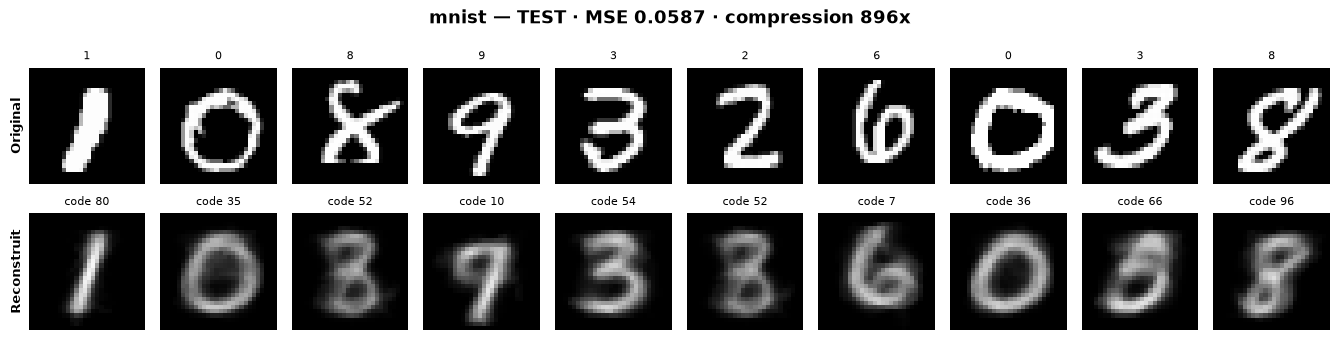

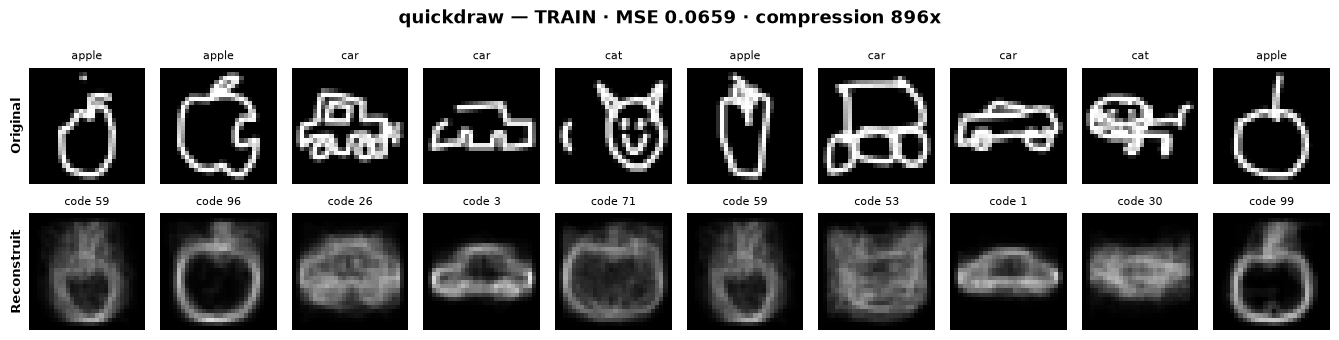

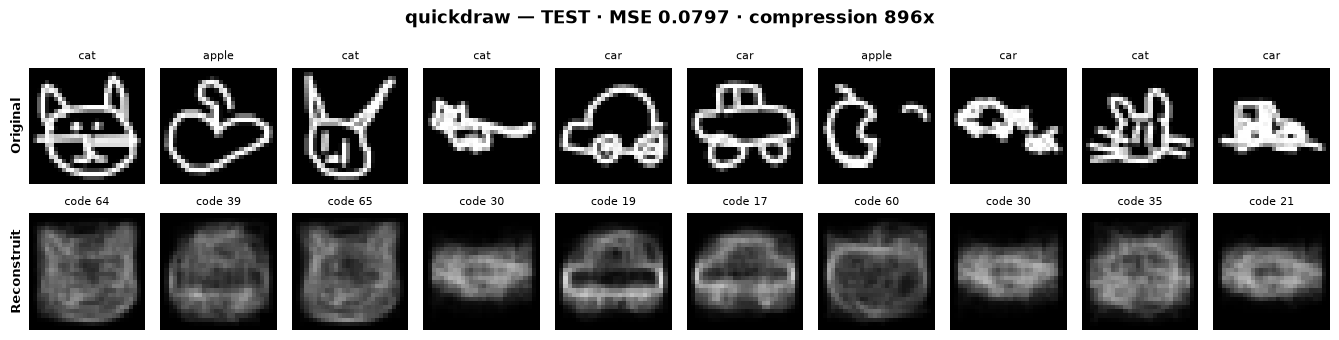

In [11]:
N_SHOW = 10
rng = np.random.default_rng(SEED)

for key, r in RESULTS.items():
    ds, W = r["ds"], r["weights"]

    for split, X_split, y_split in (("TRAIN", r["X_train"], r["y_train"]),
                                    ("TEST", ds.X_test, ds.y_test)):
        idx = rng.choice(len(X_split), size=N_SHOW, replace=False)
        originals = X_split[idx]
        codes = [encode(img, W) for img in originals]
        reconstructions = np.stack([decode(c, W) for c in codes])

        mse = mean_squared_error(originals, reconstructions)
        show_reconstructions(
            originals, reconstructions,
            top_labels=[ds.class_names[i] for i in np.asarray(y_split)[idx]],
            bottom_labels=[f"code {c}" for c in codes],
            title=f"{key} — {split} · MSE {mse:.4f} · compression {compute_compression_ratio(K):.0f}x",
        )

In [12]:
# MSE sur l'ensemble des splits : la mesure qui compte, une image ne dit rien.
print(f"{'dataset':<12} {'MSE train':>10} {'MSE test':>10}")
for key, r in RESULTS.items():
    ds, W = r["ds"], r["weights"]

    mse_train = mean_squared_error(r["X_train"], reconstruct(r["X_train"], W, r["labels"]))

    # Le test s'encode avec les poids figés : aucun réentraînement.
    labels_test = assign_clusters(ds.X_test, W)
    mse_test = mean_squared_error(ds.X_test, reconstruct(ds.X_test, W, labels_test))

    print(f"{key:<12} {mse_train:>10.4f} {mse_test:>10.4f}")

dataset       MSE train   MSE test
mnist            0.0440     0.0447
quickdraw        0.0684     0.0689


## 6. Registry — sauvegarde des modèles

Un modèle = les feature vectors `(k, 784)` + ses métadonnées, dans un `.npz` sous `models/`.

La forme de la grille fait partie des métadonnées : sans elle, les poids ne sont qu'une liste de `k` prototypes et toute la topologie — donc les visualisations — est perdue.

In [13]:
for key, r in RESULTS.items():
    name = f"{key}_som{ROWS}x{COLS}_n{len(r['X_train'])}"
    path = save_model(
        name,
        r["weights"],
        {
            "algo": "kohonen",
            "dataset": key,
            "rows": ROWS,
            "cols": COLS,
            "topology": TOPOLOGY,
            "k": K,
            "n_samples": len(r["X_train"]),
            "alpha": ALPHA,
            "gamma": GAMMA,
            "n_epochs": N_EPOCHS,
            "seed": SEED,
            "inertia": r["history"][-1],
            "history": r["history"],
            "class_names": r["ds"].class_names,
        },
    )
    r["name"] = name
    print(f"{name} -> {path.name}")

print("\nModèles disponibles :", list_models())

mnist_som10x10_n10000 -> mnist_som10x10_n10000.npz
quickdraw_som10x10_n10000 -> quickdraw_som10x10_n10000.npz

Modèles disponibles : ['mnist_som10x10_n10000', 'quickdraw_som10x10_n10000']


In [14]:
# Relecture : un modèle chargé se réutilise sans réentraînement.
W_loaded, meta = load_model(RESULTS["mnist"]["name"])

print(f"Poids identiques : {np.allclose(W_loaded, RESULTS['mnist']['weights'])}")
print(f"Grille {meta['rows']}x{meta['cols']} · MSE {mse_from_inertia(meta['inertia'], meta['n_samples']):.4f}")
print(f"Encodage avec le modèle rechargé : code {encode(RESULTS['mnist']['X_train'][0], W_loaded)}")

Poids identiques : True
Grille 10x10 · MSE 0.0440
Encodage avec le modèle rechargé : code 75


## 7. Génération des figures

Écrit toutes les figures d'un modèle en PNG 150 dpi sous `figures/<nom du modèle>/`, prêtes pour le rapport.

In [15]:
FIGURES_DIR = Path.cwd() / "figures"


def generate_figures(key, n_viz=2000, n_images=10, seed=SEED):
    """Génère et enregistre toutes les figures du modèle entraîné sur `key`."""
    r = RESULTS[key]
    ds, W = r["ds"], r["weights"]
    out_dir = FIGURES_DIR / r["name"]
    out_dir.mkdir(parents=True, exist_ok=True)

    def emit(filename, fig):
        fig.savefig(out_dir / filename, dpi=150, bbox_inches="tight")
        # Sans close, les figures s'accumulent en mémoire et matplotlib finit
        # par avertir au-delà de 20 ouvertes.
        plt.close(fig)
        return filename

    saved = []
    # show=False : on veut la figure comme objet à enregistrer, pas un rendu
    # dans le notebook — les cellules ci-dessus l'ont déjà affichée.
    saved.append(emit("01_courbe_inertie.png", plot_inertia(
        r["history"], n_samples=len(r["X_train"]), image_dim=IMAGE_DIM,
        title=f"Courbe d'entraînement — {key}", show=False)))

    saved.append(emit("02_carte_feature_vectors.png", plot_prototype_map(
        W, ROWS, COLS, cluster_labels=r["labels"], y_true=r["y_train"],
        class_names=ds.class_names, topology=TOPOLOGY,
        title=f"Carte de Kohonen — feature vectors ({key})", show=False)))


    saved.append(emit("02b_umatrix.png", plot_heatmap(
        W, ROWS, COLS, cluster_labels=r["labels"], color_by="umatrix",
        topology=TOPOLOGY, title=f"Carte de Kohonen — U-matrix ({key})",
        show=False)))

    saved.append(emit("03_espace_latent_train.png", plot_latent_space(
        r["X_train"][:n_viz], W, ROWS, COLS, y_true=r["y_train"][:n_viz],
        class_names=ds.class_names, topology=TOPOLOGY, y_label=r["y_label"],
        title=f"Espace latent — TRAIN ({key})", show=False)))

    n_test = min(n_viz, len(ds.X_test))
    saved.append(emit("04_espace_latent_test.png", plot_latent_space(
        ds.X_test[:n_test], W, ROWS, COLS, y_true=ds.y_test[:n_test],
        class_names=ds.class_names, topology=TOPOLOGY, y_label=r["y_label"],
        title=f"Espace latent — TEST ({key})", show=False)))

    saved.append(emit("05_distribution_train.png", plot_class_distribution(
        r["labels"], r["y_train"], class_names=ds.class_names, k=K, normalize=True,
        title=f"Distribution des classes réelles par neurone — {key}", show=False)))

    rng = np.random.default_rng(seed)
    for i, (split, X_split, y_split) in enumerate(
        (("train", r["X_train"], r["y_train"]), ("test", ds.X_test, ds.y_test))
    ):
        idx = rng.choice(len(X_split), size=n_images, replace=False)
        originals = X_split[idx]
        codes = [encode(img, W) for img in originals]
        reconstructions = np.stack([decode(c, W) for c in codes])
        mse = mean_squared_error(originals, reconstructions)
        saved.append(emit(f"0{6 + i}_codec_{split}.png", show_reconstructions(
            originals, reconstructions,
            top_labels=[ds.class_names[j] for j in np.asarray(y_split)[idx]],
            bottom_labels=[f"code {c}" for c in codes],
            title=f"{key} — {split.upper()} · MSE {mse:.4f}", show=False)))

    print(f"{len(saved)} figures -> {out_dir}")
    for f in saved:
        print(f"  {f}")


for key in RESULTS:
    generate_figures(key)

8 figures -> C:\Users\lucho\Documents\cours\dlu\Unsupervised_Deep_Learning\src\kohonen\figures\mnist_som10x10_n10000
  01_courbe_inertie.png
  02_carte_feature_vectors.png
  02b_umatrix.png
  03_espace_latent_train.png
  04_espace_latent_test.png
  05_distribution_train.png
  06_codec_train.png
  07_codec_test.png


8 figures -> C:\Users\lucho\Documents\cours\dlu\Unsupervised_Deep_Learning\src\kohonen\figures\quickdraw_som10x10_n10000
  01_courbe_inertie.png
  02_carte_feature_vectors.png
  02b_umatrix.png
  03_espace_latent_train.png
  04_espace_latent_test.png
  05_distribution_train.png
  06_codec_train.png
  07_codec_test.png


## Ce qu'il faut retenir

À `k` égal, le SOM affiche une **MSE un peu plus haute** que le K-means. Ce n'est pas un défaut d'entraînement : le K-means ne minimise que l'erreur de reconstruction, le SOM la minimise **sous la contrainte** que les neurones voisins restent proches. On paie un peu de compression pour obtenir une carte organisée.

Ce qu'on achète en échange : **la position d'un code a un sens**. Deux codes voisins sur la grille décodent des images qui se ressemblent, ce qui est faux pour deux codes voisins d'un K-means, dont la numérotation est arbitraire.

Cela se voit à deux endroits :

- **La carte des feature vectors** (section 2) se lit comme une carte : les variantes d'un même chiffre occupent une région connexe, et les formes intermédiaires se rangent aux frontières. La même vue pour un K-means n'est qu'une grille d'affichage arbitraire.
- **Le maillage** dans l'espace latent (section 3) montre comment la grille se replie à travers les données. Un K-means n'a rien à y montrer que ses croix.